# The GIS toolbox a mesh unlocks

`pyramids-mesh` is a **driver layer**: it parses hydrodynamic / hydraulic mesh files (2DM, Selafin,
DFSU, HEC-RAS, TUFLOW FV, SRH-2D, Gmsh, ...) and hands you back a `pyramids.netcdf.ugrid.UgridDataset`.
That return type is the whole point — once a file is read, the **entire `pyramids` UGRID toolbox**
applies: plotting, mesh geometry, vector interop, graph/topology, spatial subsetting, rasterisation
and sampling, and export. This tutorial reads two real meshes and walks that toolbox end to end.

**Meshes used**

- `examples/data/tuflowfv/Cone_003.nc` (driver `tuflowfv`) — a TUFLOW FV result file carrying real
  per-face variables (depth `D`, water level `H`, velocity `V_x`/`V_y`, bed `ZB`, and their maxima).
  We use it for every data-dependent operation, with the static variable **`max_H`** (maximum water
  surface) as the working variable.
- `examples/data/gmsh/insulated-2.2.msh` (driver `gmsh`) — a clean 111-triangle Gmsh mesh with no
  results, used for the pure-geometry section.

In [1]:
import os; os.environ["MPLBACKEND"] = "Agg"
import matplotlib; matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path
from pyramids.netcdf.ugrid import UgridDataset
DATA = Path("../../examples/data")

The cell above fixes a non-interactive Matplotlib backend (`Agg`) so nothing opens a GUI window.
Plotting through `pyramids`/`cleopatra` keeps the backend on `Agg`, which means a bare `plt.show()`
would not embed anything in the notebook. So we register the inline figure formatter once with
`%matplotlib inline` and define a tiny `show()` helper that **displays the current figure explicitly**
— that embeds every figure below, whether it was drawn by cleopatra, GeoPandas or plain Matplotlib.

In [2]:
%matplotlib inline
from IPython.display import display

def show():
    """Embed the current Matplotlib figure, then clear it."""
    display(plt.gcf())
    plt.close("all")

## 1. Read a mesh and inspect it

Reading is a single call: `UgridDataset.read_file(path, driver=...)`. The returned object already
knows its mesh size, spatial extent, coordinate reference system, and which data variables the driver
recovered. `data_variable_names` is the first thing to check — it tells you which fields you can map,
sample or export.

In [3]:
ds = UgridDataset.read_file(str(DATA / "tuflowfv" / "Cone_003.nc"), driver="tuflowfv")
VAR = "max_H"  # maximum water-surface elevation, one static value per face
print("faces :", ds.n_face, " nodes:", ds.n_node)
print("bounds:", tuple(round(b, 2) for b in ds.bounds))
print("crs   :", ds.crs)
print("variables:", ds.data_variable_names)

faces : 2866  nodes: 1497
bounds: (-0.59, -0.55, 200.59, 200.61)
crs   : None
variables: ['D', 'H', 'V_x', 'V_y', 'ZB', 'max_D', 'max_H', 'max_V_x', 'max_V_y', 'max_ZB', 'maxtime_D', 'maxtime_H', 'maxtime_V', 'maxtime_ZB', 'stat', 'node_z']


C:\python-environments\pixi\envs\pyramids-mesh-4081970794675243037\envs\dev\Lib\site-packages\pyramids\netcdf\ugrid\_drivers.py:538: RuntimeWarning: Mesh driver 'dfsu' (pyramids_mesh.drivers.dhi:DfsuDriver) could not be loaded and was skipped: ModuleNotFoundError("No module named 'mikeio'")
  driver = _instantiate(entry_point)


`summary()` returns a pandas DataFrame of per-variable statistics — a quick way to see the range
of each field before plotting. Here we summarise the three static maxima fields.

In [4]:
ds.summary(variables=["max_H", "max_D", "max_ZB"])

,count,min,max,mean,std
variable,,,,,
max_H,2844,3.211602,97.256569,33.256129,23.385387
max_D,2844,0.010034,2.007636,0.121414,0.367166
max_ZB,2866,1.205051,97.219559,33.082184,23.449038


**Interpret.** The file exposes 16 variables; `max_H` ranges ~3–97 m. Note `crs` is `None` — the
TUFLOW FV file carries no CRS metadata. That does not block any geometry or plotting below; it only
means a reprojection (`to_crs`) has nothing to work from, which we handle in section 7.

## 2. Plotting the mesh

The dataset plots itself. `plot_outline()` draws just the mesh boundary; `plot(variable, ...)` draws a
filled choropleth of a per-face field, routed through `cleopatra` (reached via `pyramids` — this
package writes no Matplotlib code of its own). `cmap`, `colorbar`, `title` and an optional `contour`
spec are all accepted.

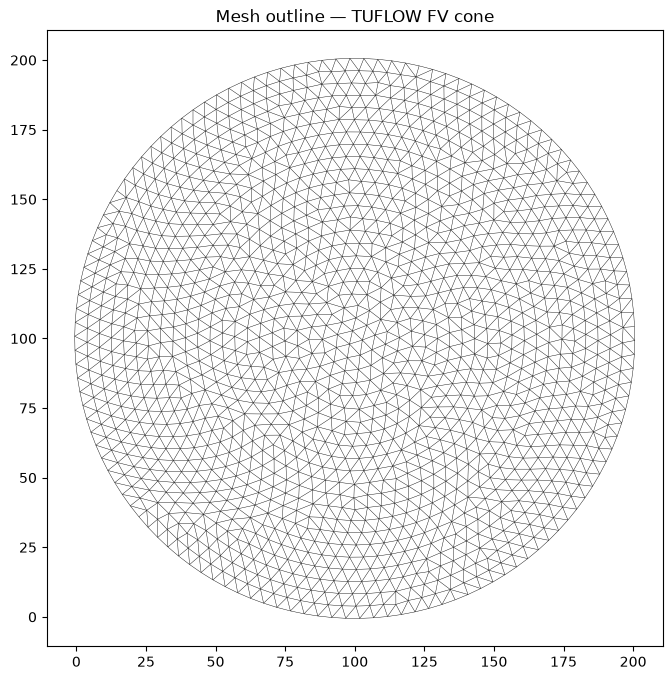

In [5]:
ds.plot_outline()
plt.title("Mesh outline — TUFLOW FV cone")
show()

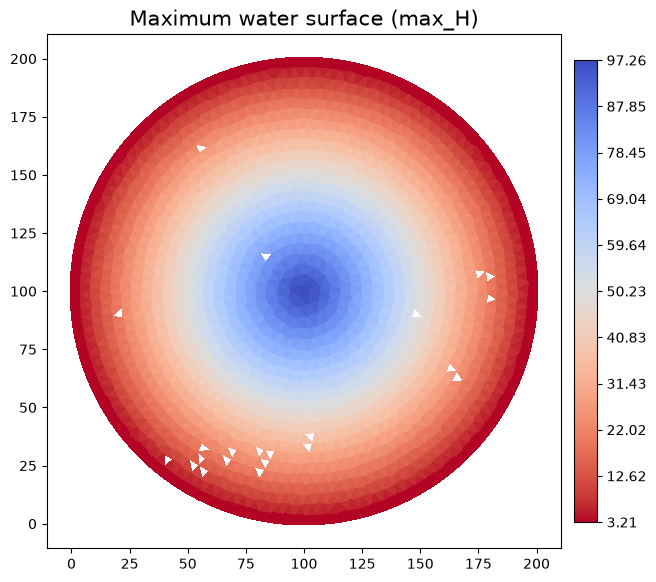

In [6]:
ds.plot(VAR, cmap="viridis", colorbar=True, title="Maximum water surface (max_H)")
show()

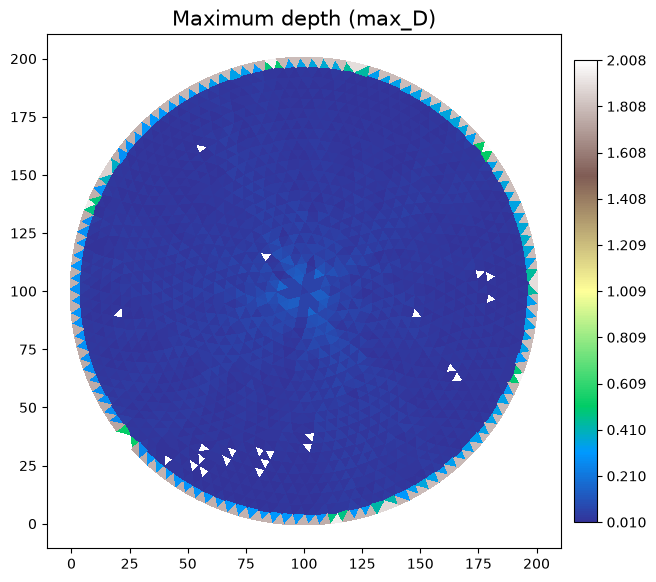

In [7]:
ds.plot("max_D", cmap="terrain", colorbar=True, title="Maximum depth (max_D)")
show()

A contour overlay is added with a `Contour` spec from `pyramids.plot`.

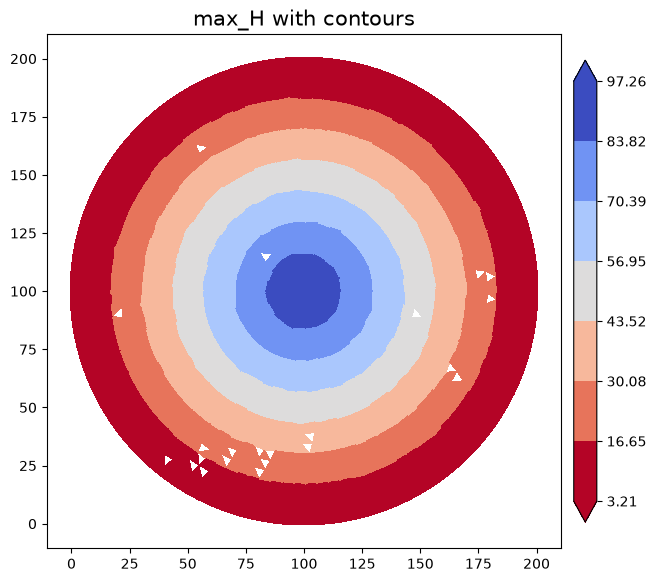

In [8]:
from pyramids.plot import Contour
ds.plot(VAR, cmap="viridis", colorbar=True, title="max_H with contours", contour=Contour(levels=8))
show()

**Interpret.** The cone geometry is obvious in the outline; `max_H` and `max_D` show the radial
gradient from the peak. Switching the colormap (`viridis` vs `terrain`) and overlaying contour lines
are one-keyword changes — the mesh topology is handled for you.

## 3. Mesh geometry

Geometry derives straight from the topology, so it needs no result variables — we use the clean Gmsh
triangle mesh here. The `.mesh` accessor exposes `face_areas`, `face_centroids` (returned as a
`(2, n)` pair of x/y arrays), and the dataset offers `circumcenters()`, `bounding_polygon()` (a shapely
`Polygon`) and `exterior_edges()` (indices of the boundary edges).

In [9]:
gm = UgridDataset.read_file(str(DATA / "gmsh" / "insulated-2.2.msh"), driver="gmsh")
areas = np.asarray(gm.mesh.face_areas)
cx, cy = gm.mesh.face_centroids
cc = gm.circumcenters()
print("faces:", gm.n_face, " total area:", round(areas.sum(), 3))
print("centroids:", np.asarray((cx, cy)).shape, " circumcenters:", cc.shape)

faces: 111  total area: 27.854
centroids: (2, 111)  circumcenters: (111, 2)


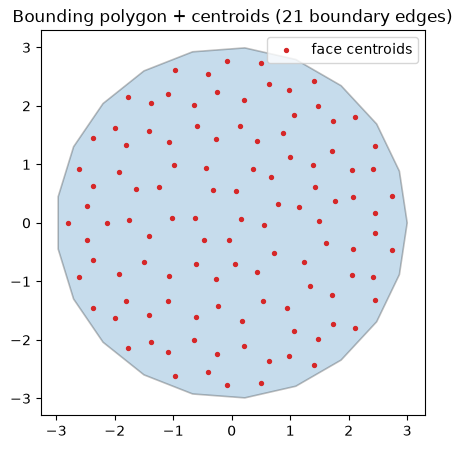

In [10]:
poly = gm.bounding_polygon()
edges = gm.exterior_edges()
bx, by = poly.exterior.xy
fig, ax = plt.subplots(figsize=(5, 5))
ax.fill(bx, by, alpha=0.25, edgecolor="black", linewidth=1.2)
ax.scatter(cx, cy, s=8, c="C3", label="face centroids")
ax.set_aspect("equal"); ax.set_title(f"Bounding polygon + centroids ({edges.size} boundary edges)")
ax.legend(); show()

**Interpret.** `face_areas` sums to the mesh area; `face_centroids` and `circumcenters` give one
point per triangle. `bounding_polygon()` returns the dissolved outline as a shapely geometry (so it
composes with any shapely/geopandas workflow), and `exterior_edges()` identifies the boundary.

## 4. Vector interop

A mesh with a variable converts straight to vector formats. `to_geodataframe(variable_name=...)` yields
a GeoPandas `GeoDataFrame` (one polygon per face plus the variable column) — so the whole GeoPandas /
shapely ecosystem is available. `to_feature_collection(...)` returns pyramids' own `FeatureCollection`.

In [11]:
gdf = ds.to_geodataframe(variable_name=VAR)
gdf.head()

,max_H,geometry
0,3.212479,"POLYGON ((19.36256 39.8936, 22.46044 35.94882,..."
1,3.212720,"POLYGON ((25.75109 32.16335, 29.18528 35.06804..."
2,3.212404,"POLYGON ((29.18528 35.06804, 25.75109 32.16335..."
3,5.516877,"POLYGON ((29.24278 41.01716, 22.88029 42.68976..."
4,3.212687,"POLYGON ((25.75109 32.16335, 25.2713 38.28082,..."


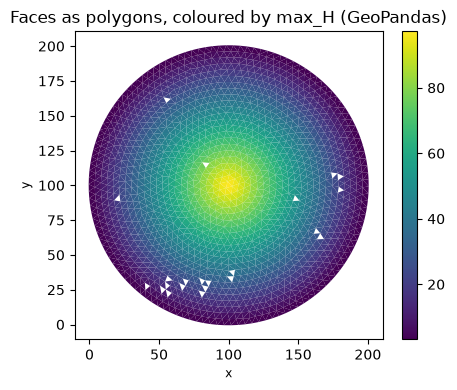

FeatureCollection(2866 features, columns=['max_H', 'geometry'], epsg=None)


In [12]:
gdf.plot(column=VAR, cmap="viridis", legend=True, figsize=(5, 4))
plt.title("Faces as polygons, coloured by max_H (GeoPandas)")
show()
fc = ds.to_feature_collection(variable_name=VAR)
print(fc)

**Interpret.** Each face becomes a polygon feature carrying `max_H`. Rendering via
`GeoDataFrame.plot(column=...)` confirms the same spatial pattern, now in a standard vector object you
can join, dissolve, buffer or write to a shapefile/GeoPackage. The `FeatureCollection` is the
pyramids-native equivalent (note `epsg=None`, mirroring the mesh's missing CRS).

## 5. Topology and graph structure

A mesh is a graph of faces. `sparse_adjacency()` returns a SciPy CSR matrix of face-to-face
adjacency, and `connected_components()` labels each face by its connected region — useful to detect
whether a mesh is one piece or several disjoint blocks.

In [13]:
A = ds.sparse_adjacency(kind="face")
labels = ds.connected_components()
print("adjacency:", A.shape, " non-zeros:", A.nnz)
print("neighbours per face: min", A.getnnz(axis=1).min(), "max", A.getnnz(axis=1).max())
print("connected components:", np.unique(labels).size)

adjacency: (2866, 2866)  non-zeros: 8472
neighbours per face: min 2 max 3
connected components: 1


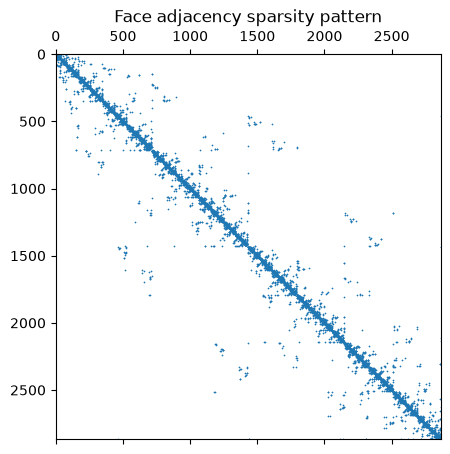

In [14]:
fig, ax = plt.subplots(figsize=(5, 5))
ax.spy(A, markersize=0.3)
ax.set_title("Face adjacency sparsity pattern")
show()

**Interpret.** The adjacency matrix is `n_face x n_face` and very sparse (each face touches only
its handful of edge-neighbours). A single connected component confirms the cone mesh is one contiguous
piece. The CSR matrix feeds directly into SciPy graph algorithms (shortest path, Laplacians, ...).

## 6. Spatial subsetting

Two ways to cut the mesh to a region of interest: `subset_by_bounds(xmin, ymin, xmax, ymax)` and
`crop(bbox=(...))`. Both return a smaller `UgridDataset` that still carries the variables, so you can
plot or export the subset exactly like the full mesh.

subset faces: 889 of 2866


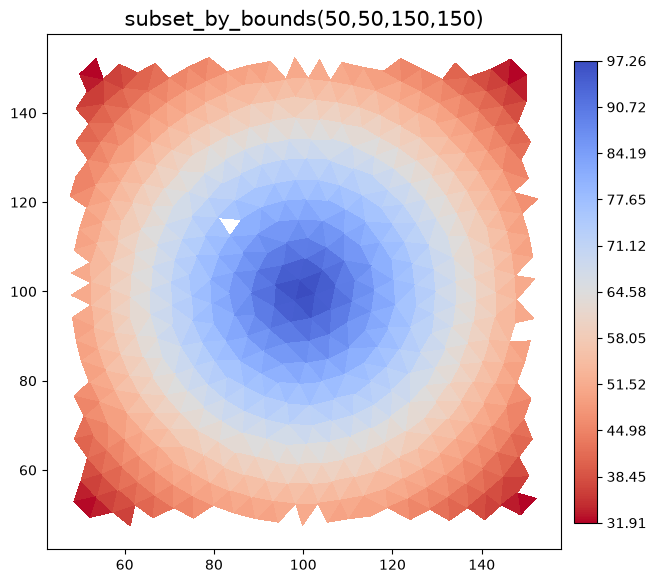

In [15]:
sub = ds.subset_by_bounds(50, 50, 150, 150)
print("subset faces:", sub.n_face, "of", ds.n_face)
sub.plot(VAR, cmap="viridis", colorbar=True, title="subset_by_bounds(50,50,150,150)")
show()

cropped faces: 718


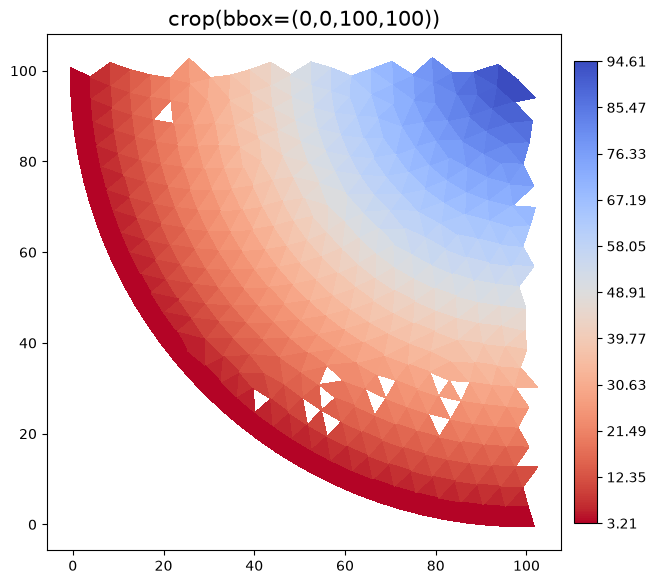

In [16]:
cropped = ds.crop(bbox=(0, 0, 100, 100))
print("cropped faces:", cropped.n_face)
cropped.plot(VAR, cmap="viridis", colorbar=True, title="crop(bbox=(0,0,100,100))")
show()

**Interpret.** Each call keeps only the faces intersecting the window and returns a live dataset,
so downstream analysis runs on the clipped mesh without any manual bookkeeping of node/face indices.

## 7. Rasterisation, vectorisation and sampling

Once a variable is in hand you can move it between representations:

- `polygonize(variable)` — dissolve equal-valued faces into vector polygons.
- `sample(variable, x, y)` — point query: read the variable at arbitrary coordinates.
- `to_dataset(variable, cell_size)` — rasterise the field onto a regular grid (a pyramids `Dataset`).

In [17]:
pg = ds.polygonize(VAR)
print("polygonize ->", type(pg).__name__, "with", len(pg), "polygons")
pg.head()

polygonize -> GeoDataFrame with 2842 polygons


,value,geometry
0,3.211602,"POLYGON ((9.04533 57.06436, 11.30013 52.58396,..."
1,3.211729,"POLYGON ((9.04533 57.06436, 14.82653 55.40669,..."
2,3.211758,"POLYGON ((11.30013 52.58396, 13.77546 48.22152..."
3,3.211799,"POLYGON ((17.26545 51.03883, 14.82653 55.40669..."
4,3.211832,"POLYGON ((12.61853 59.89453, 7.01666 61.65158,..."


In [18]:
# query max_H at three interior points (reuse a few face centroids as sample locations)
fcx, fcy = np.asarray(ds.mesh.face_centroids)
px, py = fcx[[100, 1000, 2000]], fcy[[100, 1000, 2000]]
vals = ds.sample(VAR, px, py)
for x, y, v in zip(px, py, vals):
    print(f"  ({x:7.2f}, {y:7.2f}) -> max_H = {v:.3f}")

  (  51.69,   13.51) -> max_H = 3.215
  (  55.03,  139.03) -> max_H = 40.791
  ( 167.46,   72.93) -> max_H = 27.719


In [19]:
rast = ds.to_dataset(VAR, cell_size=5.0)
print("rasterised ->", type(rast).__name__, "shape", rast.shape)

rasterised -> Dataset shape (1, 41, 41)


**Interpret.** `polygonize` turns the field into ~2800 vector polygons; `sample` returns the
per-point values; `to_dataset` burns the mesh onto a 5-unit grid (a `(1, 41, 41)` raster `Dataset`).

**Shown-and-skipped (missing inputs).**

- `ds.rasterize_like(reference, VAR)` and `ds.regrid(target, variable_name=VAR)` need an **existing
  target grid/mesh** to align to. We have no reference raster here, so these are not run — the call
  shape is `ds.rasterize_like(some_dataset, "max_H")`. `to_dataset` above is the self-contained
  alternative when you just need *a* grid rather than one matching a specific reference.
- `ds.to_crs(epsg)` needs a source CRS to project *from*; this mesh's `crs` is `None`
  (see section 1), so there is nothing to reproject and the call is skipped.

## 8. Export

Finally, write the mesh back out. `to_file(path, driver=...)` writes any MDAL-supported format (here
a 2DM), and `to_xarray()` hands the dataset to the xarray ecosystem for NetCDF / Zarr workflows.

In [20]:
import tempfile
out = Path(tempfile.gettempdir()) / "cone_out.2dm"
ds.to_file(str(out), driver="2dm")
print("wrote:", out.name, "->", out.stat().st_size, "bytes, exists:", out.exists())
xds = ds.to_xarray()
print("to_xarray ->", type(xds).__module__ + "." + type(xds).__name__)

wrote: cone_out.2dm -> 142727 bytes, exists: True
to_xarray -> xarray.core.dataset.Dataset


**Interpret.** The round-trip is complete: a file read by a `pyramids-mesh` driver became a
`UgridDataset`, flowed through the full pyramids GIS/visualisation toolbox, and was written back to a
mesh file and to an xarray `Dataset`. That return type — not any one operation — is what the plugin
buys you: every capability above comes from `pyramids`, unlocked the moment the file is parsed.